PHISHING DETECTION AVEC LIGHTGBM ET CNN - ANALYSE AVANCÉE
Dimensions du dataset: 10000 lignes × 50 colonnes


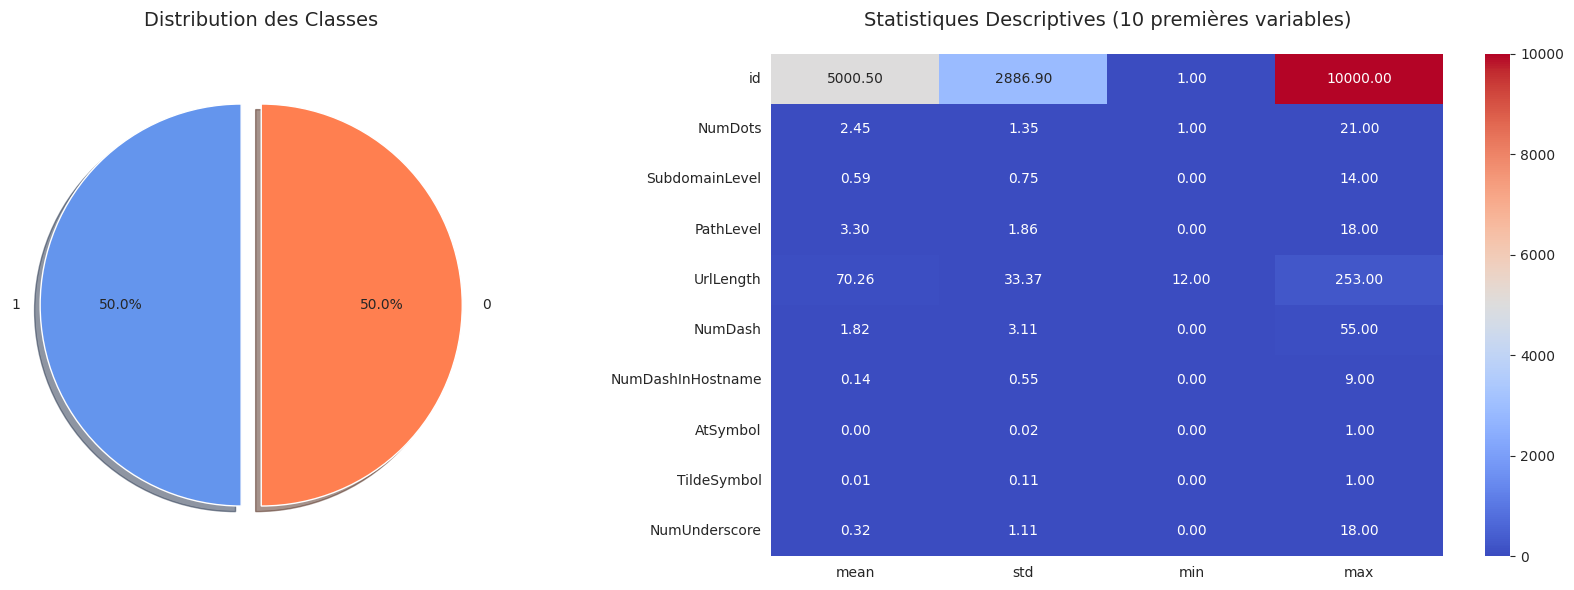


PRÉPARATION ET PRÉTRAITEMENT DES DONNÉES

Valeurs manquantes par colonne:
Aucune valeur manquante

Nombre de caractéristiques initiales: 48
Distribution initiale des classes: {1: 5000, 0: 5000}


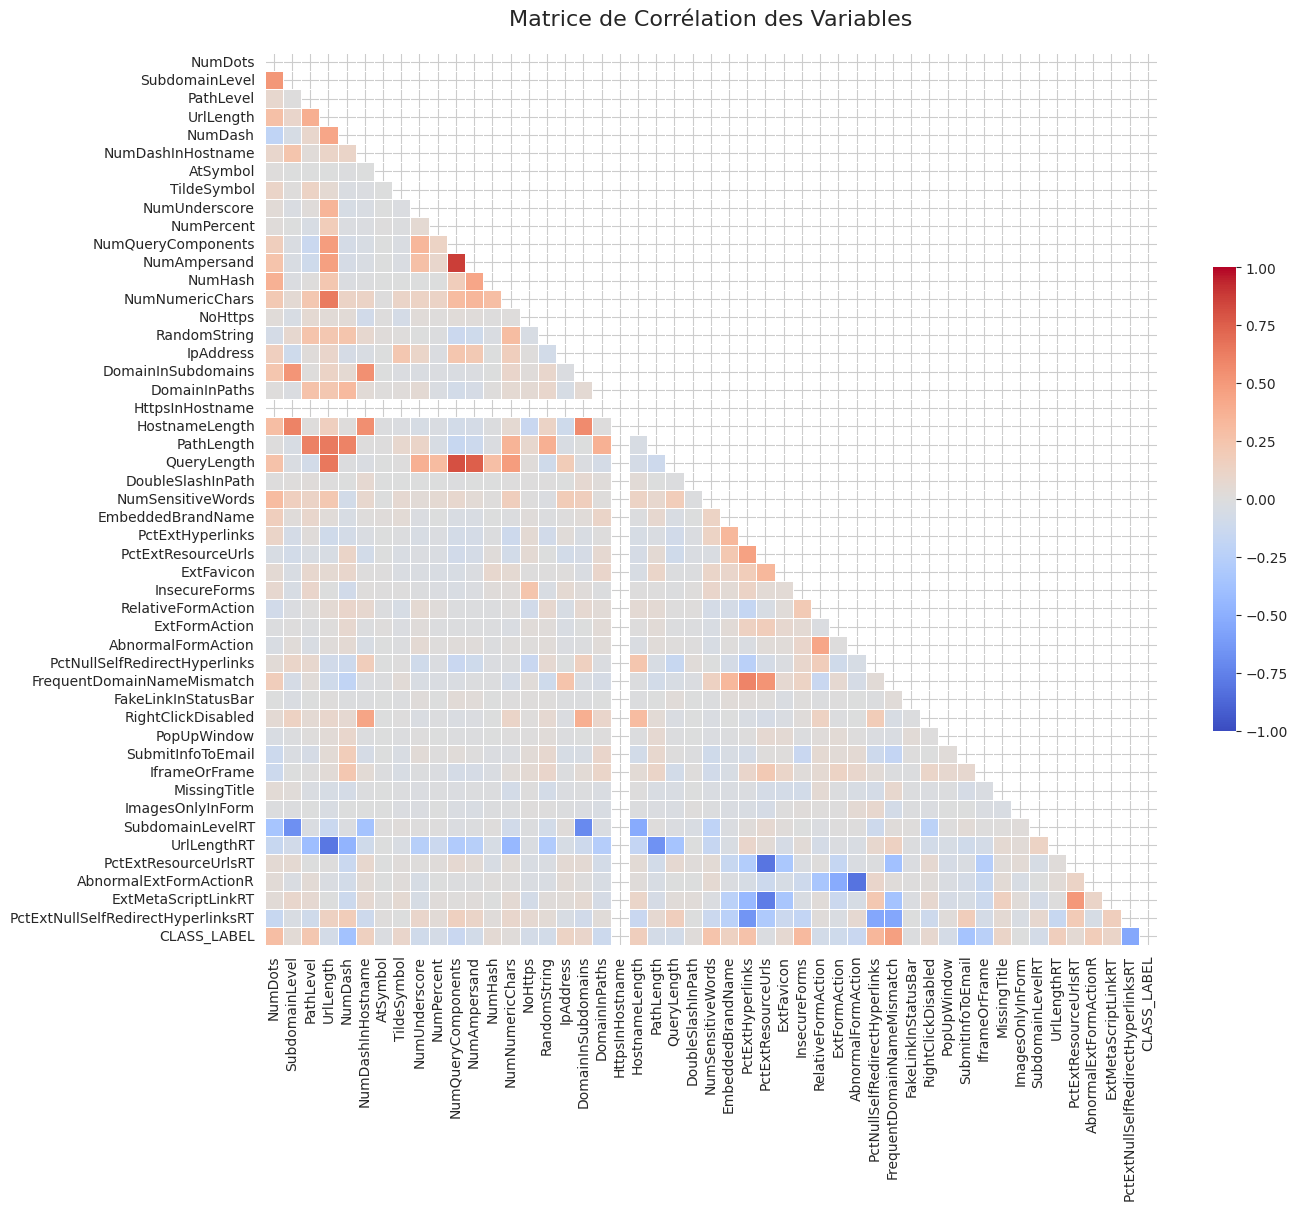


Application de transformations pour normaliser les distributions...
Transformations appliquées.

Détection d'anomalies avec IsolationForest:


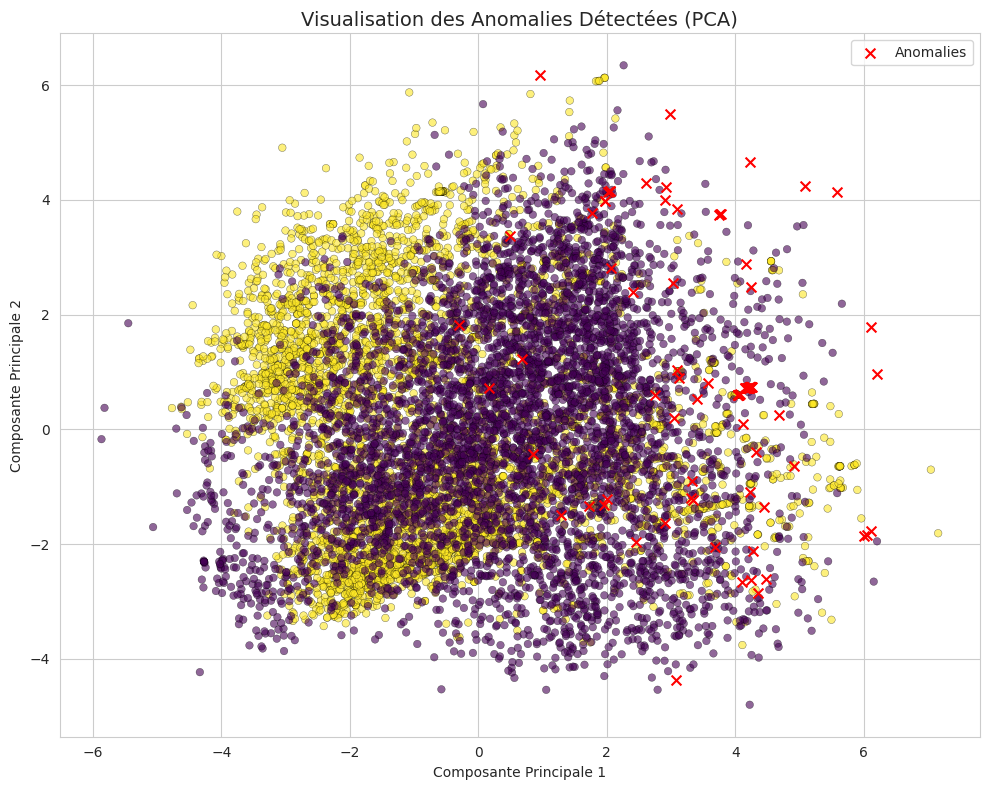

Points supprimés comme anomalies: 99 (0.99%)

Équilibrage des classes avec SMOTE...


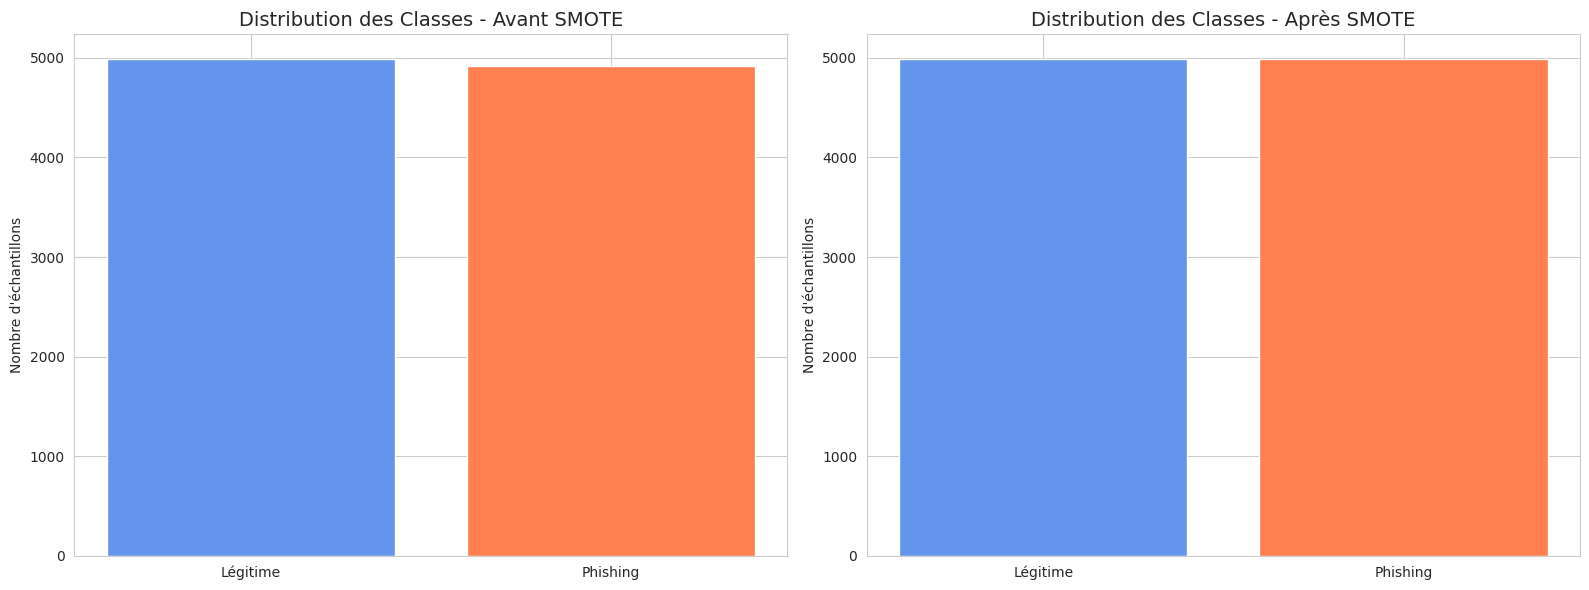

Distribution des classes après SMOTE: [4987 4987]

SÉLECTION DE CARACTÉRISTIQUES AVEC F_CLASSIFIER

Exécution de la sélection de features avec F_classifier...

Top 15 features selon le F-test:
                               Feature    F_Score      P_Value
47  PctExtNullSelfRedirectHyperlinksRT  3327.3906   0.0000e+00
34          FrequentDomainNameMismatch  2761.5177   0.0000e+00
38                   SubmitInfoToEmail  1469.7571  4.2809e-300
0                              NumDots  1240.5603  3.0237e-256
4                              NumDash  1157.3899  4.1293e-240
29                       InsecureForms  1139.6170  1.2012e-236
24                   NumSensitiveWords   745.4715  2.3378e-158
13                     NumNumericChars   732.1436  1.1666e-155
2                            PathLevel   721.7150  1.5153e-153
39                       IframeOrFrame   627.7726  2.0673e-134
10                  NumQueryComponents   604.7562  1.0717e-129
22                         QueryLength   538.0983  

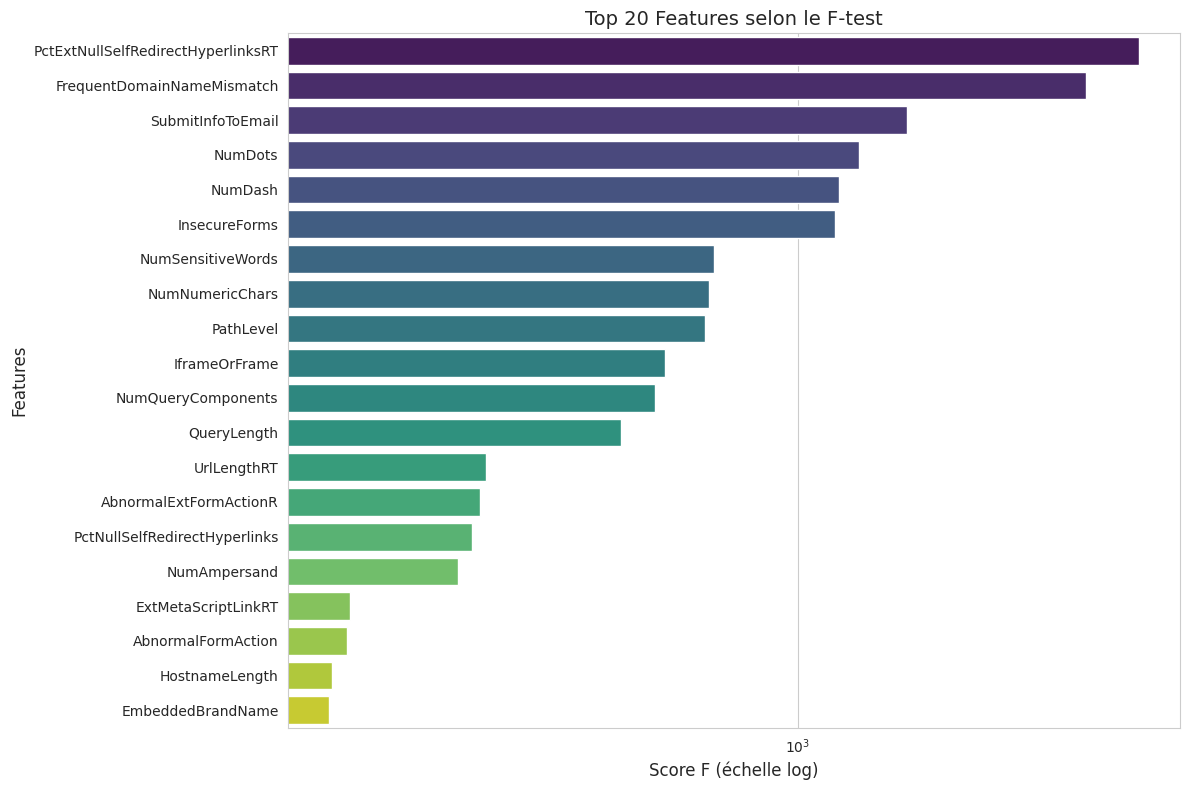


Recherche du nombre optimal de caractéristiques...
[LightGBM] [Info] Number of positive: 3989, number of negative: 3990
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000697 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 61
[LightGBM] [Info] Number of data points in the train set: 7979, number of used features: 5
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499937 -> initscore=-0.000251
[LightGBM] [Info] Start training from score -0.000251
[LightGBM] [Info] Number of positive: 3989, number of negative: 3990
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000410 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 58
[LightGBM] [Info] Number of data points in the train set: 7979, numbe

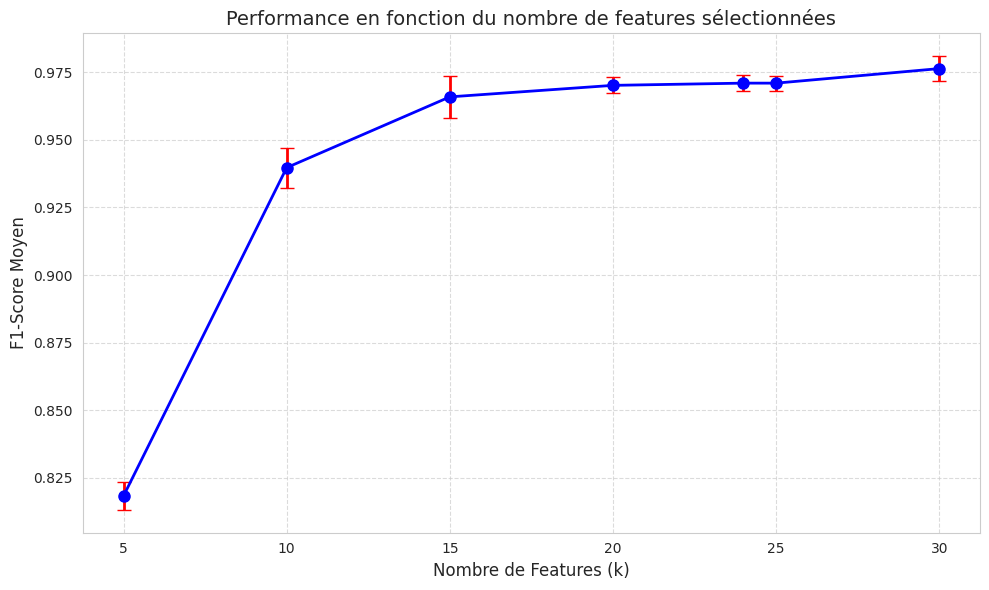


Meilleur nombre de features (k): 30
F1-Score avec 30 features: 0.9764

Les 30 meilleures features sélectionnées par F_classifier:
1. NumDots
2. PathLevel
3. UrlLength
4. NumDash
5. NumDashInHostname
6. TildeSymbol
7. NumUnderscore
8. NumQueryComponents
9. NumAmpersand
10. NumNumericChars
11. RandomString
12. IpAddress
13. DomainInPaths
14. HostnameLength
15. QueryLength
16. NumSensitiveWords
17. EmbeddedBrandName
18. PctExtResourceUrls
19. InsecureForms
20. ExtFormAction
21. AbnormalFormAction
22. PctNullSelfRedirectHyperlinks
23. FrequentDomainNameMismatch
24. SubmitInfoToEmail
25. IframeOrFrame
26. MissingTitle
27. UrlLengthRT
28. AbnormalExtFormActionR
29. ExtMetaScriptLinkRT
30. PctExtNullSelfRedirectHyperlinksRT


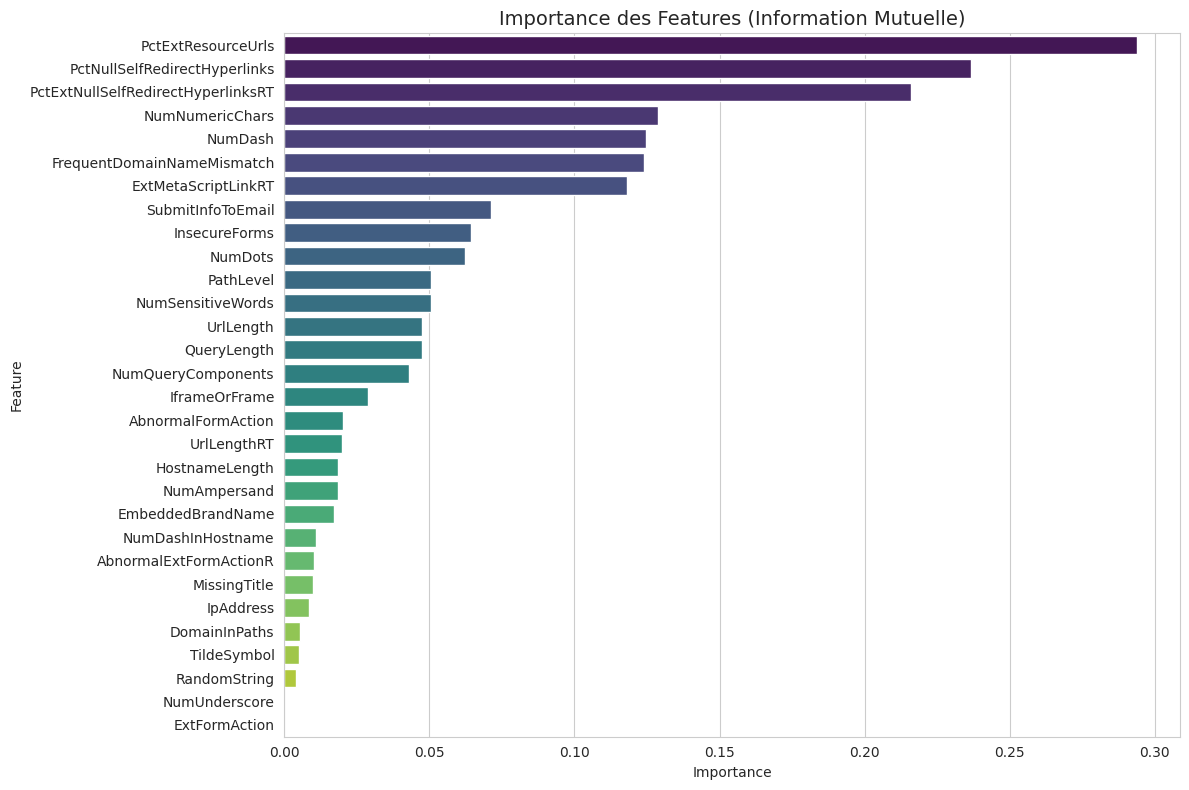


PRÉPARATION POUR L'ENTRAÎNEMENT PARALLÈLE LGBM & CNN
Dimensions de l'ensemble d'entraînement: (7979, 30)
Dimensions de l'ensemble de test: (1995, 30)

Recherche des hyperparamètres optimaux pour LightGBM...
Fitting 5 folds for each of 729 candidates, totalling 3645 fits
[LightGBM] [Info] Number of positive: 3990, number of negative: 3989
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002864 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1141
[LightGBM] [Info] Number of data points in the train set: 7979, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500063 -> initscore=0.000251
[LightGBM] [Info] Start training from score 0.000251

Meilleurs paramètres pour LGBM: {'learning_rate': 0.1, 'min_child_samples': 20, 'n_estimators': 300, 'num_leaves': 31, 'reg_alpha': 0, 'reg_lambda': 0.1}
Meilleur score de va

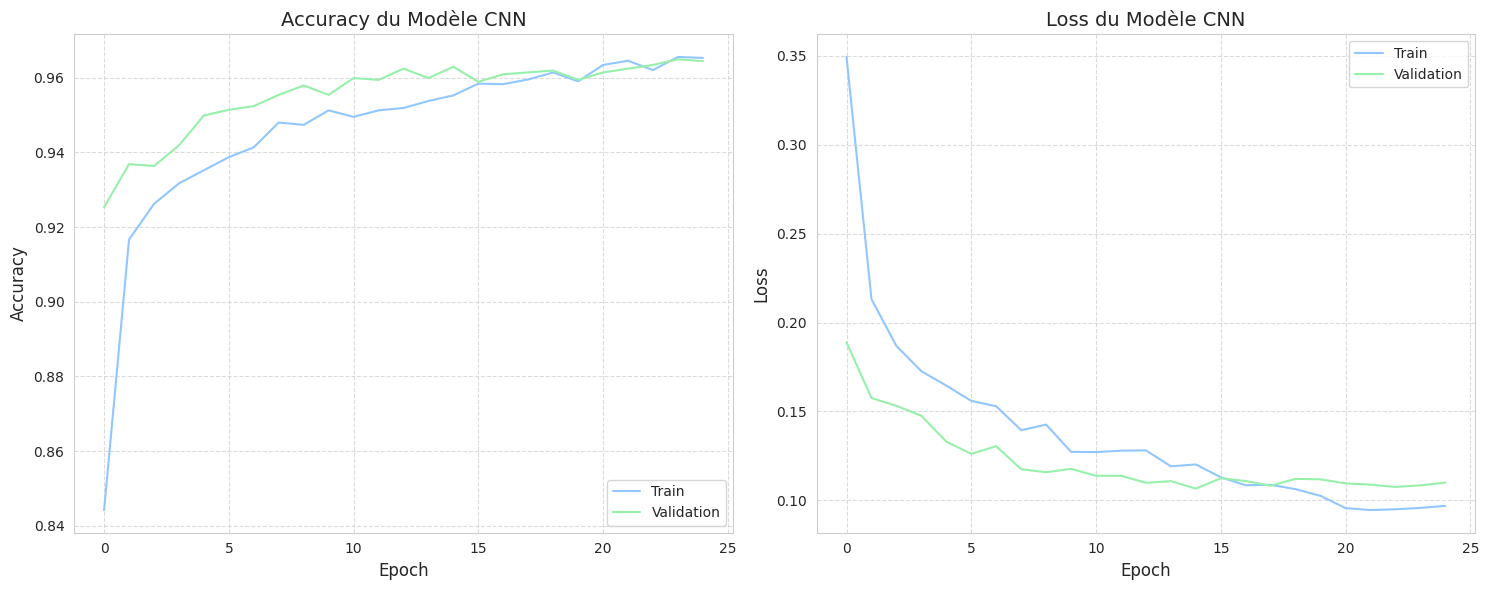


ÉVALUATION INDIVIDUELLE DES MODÈLES

--- Rapport de Classification LightGBM ---
              precision    recall  f1-score   support

           0     0.9749    0.9729    0.9739       998
           1     0.9730    0.9749    0.9739       997

    accuracy                         0.9739      1995
   macro avg     0.9739    0.9739    0.9739      1995
weighted avg     0.9739    0.9739    0.9739      1995

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

--- Rapport de Classification CNN ---
              precision    recall  f1-score   support

           0     0.9648    0.9609    0.9629       998
           1     0.9610    0.9649    0.9630       997

    accuracy                         0.9629      1995
   macro avg     0.9629    0.9629    0.9629      1995
weighted avg     0.9629    0.9629    0.9629      1995


ENSEMBLE DES MODÈLES

--- Rapport de Classification de l'Ensemble ---
              precision    recall  f1-score   support

           0     0.9741    0.9800    0.9770       998
       

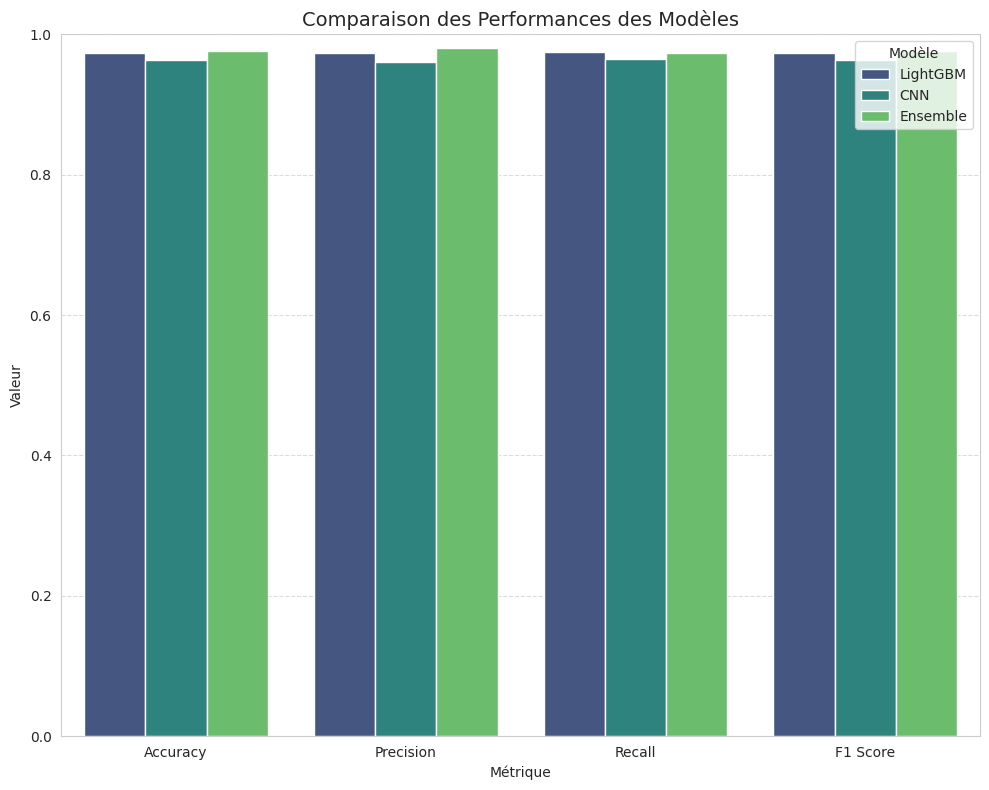

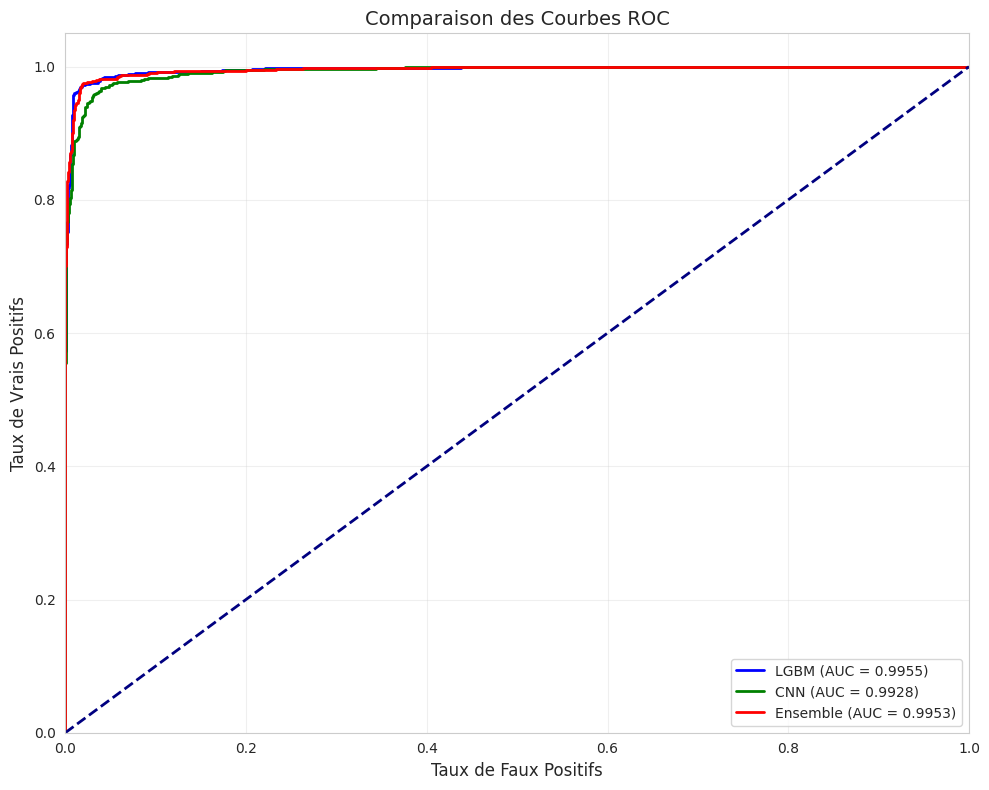


Analyse des 10 premières erreurs de l'ensemble:
Exemple 1:
  Vrai label: 0
  Prédiction Ensemble: 1 (prob: 0.8819)
  Prédiction LGBM: 1 (prob: 0.8540)
  Prédiction CNN: 1 (prob: 0.9237)

Exemple 2:
  Vrai label: 1
  Prédiction Ensemble: 0 (prob: 0.0016)
  Prédiction LGBM: 0 (prob: 0.0016)
  Prédiction CNN: 0 (prob: 0.0015)

Exemple 3:
  Vrai label: 1
  Prédiction Ensemble: 0 (prob: 0.0171)
  Prédiction LGBM: 0 (prob: 0.0192)
  Prédiction CNN: 0 (prob: 0.0139)

Exemple 4:
  Vrai label: 1
  Prédiction Ensemble: 0 (prob: 0.0759)
  Prédiction LGBM: 0 (prob: 0.0562)
  Prédiction CNN: 0 (prob: 0.1055)

Exemple 5:
  Vrai label: 0
  Prédiction Ensemble: 1 (prob: 0.9918)
  Prédiction LGBM: 1 (prob: 0.9882)
  Prédiction CNN: 1 (prob: 0.9973)

Exemple 6:
  Vrai label: 1
  Prédiction Ensemble: 0 (prob: 0.2448)
  Prédiction LGBM: 0 (prob: 0.3749)
  Prédiction CNN: 0 (prob: 0.0495)

Exemple 7:
  Vrai label: 1
  Prédiction Ensemble: 0 (prob: 0.1381)
  Prédiction LGBM: 0 (prob: 0.1107)
  Prédiction C

In [1]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, learning_curve
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.metrics import classification_report, roc_curve, auc, accuracy_score, precision_recall_curve
from sklearn.metrics import confusion_matrix, average_precision_score, f1_score, precision_score, recall_score
# Importer f_classif et SelectKBest pour remplacer RFECV
from sklearn.feature_selection import f_classif, SelectKBest, mutual_info_classif

from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.pipeline import Pipeline as ImbPipeline

# Importations pour le modèle CNN
import tensorflow as tf
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Dense, Dropout, Input, BatchNormalization, Activation
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Set display precision & style
np.set_printoptions(precision=4)
pd.set_option('display.precision', 4)
sns.set_style('whitegrid')
plt.style.use('seaborn-v0_8-pastel')

# ---------------------------
# 0. Chargement et exploration du dataset
# ---------------------------
print("="*80)
print("PHISHING DETECTION AVEC LIGHTGBM ET CNN - ANALYSE AVANCÉE")
print("="*80)

# Charger le dataset
df = pd.read_csv("Phishing_Legitimate_full.csv")

print(f"Dimensions du dataset: {df.shape[0]} lignes × {df.shape[1]} colonnes")

# Créer une figure avec deux subplots pour l'exploration initiale
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Afficher la distribution des classes
target_column = 'CLASS_LABEL' if 'CLASS_LABEL' in df.columns else 'label'
class_counts = df[target_column].value_counts()
colors = ['#6495ED', '#FF7F50']
ax1.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%',
        colors=colors, shadow=True, startangle=90, explode=(0.1, 0))
ax1.set_title('Distribution des Classes', fontsize=14, pad=20)

# Afficher les statistiques descriptives pour quelques colonnes numériques
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns[:10]
stats_df = df[numeric_columns].describe().T[['mean', 'std', 'min', 'max']]
sns.heatmap(stats_df, cmap='coolwarm', annot=True, fmt='.2f', ax=ax2)
ax2.set_title('Statistiques Descriptives (10 premières variables)', fontsize=14, pad=20)

plt.tight_layout()
plt.show()

# ---------------------------
# 1. Préparation avancée des données
# ---------------------------
print("\n" + "="*80)
print("PRÉPARATION ET PRÉTRAITEMENT DES DONNÉES")
print("="*80)

# Retirer les colonnes non pertinentes (exemple : 'id' et 'url')
for col in ['id', 'url']:
    if col in df.columns:
        df.drop(columns=[col], inplace=True)

# Vérification et traitement des valeurs manquantes
missing_values = df.isnull().sum()
print("\nValeurs manquantes par colonne:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "Aucune valeur manquante")

# Séparation des features et de la cible
X = df.drop(columns=[target_column])
y = df[target_column]
feature_names = X.columns

# Analyse des caractéristiques initiales
print(f"\nNombre de caractéristiques initiales: {X.shape[1]}")
print(f"Distribution initiale des classes: {y.value_counts().to_dict()}")

# Afficher la matrice de corrélation
plt.figure(figsize=(14, 12))
corr_matrix = df.corr()
mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', vmax=1, vmin=-1, center=0,
            square=True, linewidths=.5, annot=False, cbar_kws={'shrink': .5})
plt.title('Matrice de Corrélation des Variables', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

# ---------------------------
# 2. Prétraitement avancé: Scaling avec PowerTransformer + StandardScaler
# ---------------------------
# PowerTransformer pour normaliser les distributions
print("\nApplication de transformations pour normaliser les distributions...")
power_transformer = PowerTransformer(method='yeo-johnson')
X_transformed = power_transformer.fit_transform(X)

# Standard Scaler pour centrer et réduire
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_transformed)
print("Transformations appliquées.")

# ---------------------------
# 3. Détection et suppression des anomalies avec IsolationForest
# ---------------------------
print("\nDétection d'anomalies avec IsolationForest:")
chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42, n_jobs=-1)
pred_anomalies = iso.fit_predict(X_scaled)
mask = pred_anomalies != -1
X_clean = X_scaled[mask]
y_clean = y[mask]

# Visualisation des anomalies (PCA pour la visualisation en 2D)
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 8))
plt.scatter(X_pca[mask, 0], X_pca[mask, 1], c=y[mask], cmap='viridis', alpha=0.6, s=30, edgecolor='k', linewidth=0.3)
plt.scatter(X_pca[~mask, 0], X_pca[~mask, 1], c='red', marker='x', s=50, label='Anomalies')
plt.title('Visualisation des Anomalies Détectées (PCA)', fontsize=14)
plt.xlabel('Composante Principale 1')
plt.ylabel('Composante Principale 2')
plt.legend()
plt.tight_layout()
plt.show()

nombre_anomalies = len(X_scaled) - np.sum(mask)
print(f"Points supprimés comme anomalies: {nombre_anomalies} ({nombre_anomalies/len(X_scaled)*100:.2f}%)")

# ---------------------------
# 4. Équilibrage de la dataset avec SMOTE
# ---------------------------
print("\nÉquilibrage des classes avec SMOTE...")
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_clean, y_clean)

# Visualisation avant/après équilibrage
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Avant SMOTE
ax1.bar(['Légitime', 'Phishing'], [np.sum(y_clean == 0), np.sum(y_clean == 1)],
        color=['#6495ED', '#FF7F50'])
ax1.set_title('Distribution des Classes - Avant SMOTE', fontsize=14)
ax1.set_ylabel('Nombre d\'échantillons')

# Après SMOTE
ax2.bar(['Légitime', 'Phishing'], [np.sum(y_res == 0), np.sum(y_res == 1)],
        color=['#6495ED', '#FF7F50'])
ax2.set_title('Distribution des Classes - Après SMOTE', fontsize=14)
ax2.set_ylabel('Nombre d\'échantillons')

plt.tight_layout()
plt.show()

print(f"Distribution des classes après SMOTE: {np.bincount(y_res)}")

# ---------------------------
# 5. REMPLACEMENT DE RFECV par F_CLASSIFIER pour la sélection optimale des features
# ---------------------------
print("\n" + "="*80)
print("SÉLECTION DE CARACTÉRISTIQUES AVEC F_CLASSIFIER")
print("="*80)

# Appliquer le F-test pour évaluer l'importance des features
print("\nExécution de la sélection de features avec F_classifier...")
f_scores, p_values = f_classif(X_res, y_res)

# Création d'un DataFrame pour visualiser les scores F et les p-values
feature_selection_df = pd.DataFrame({
    'Feature': feature_names,
    'F_Score': f_scores,
    'P_Value': p_values
})

# Trier par score F décroissant
feature_selection_df = feature_selection_df.sort_values('F_Score', ascending=False)

# Afficher les résultats
print("\nTop 15 features selon le F-test:")
print(feature_selection_df.head(15))

# Visualisation des scores F des features
plt.figure(figsize=(12, 8))
top_k = min(20, len(feature_names))  # Assurer qu'on ne demande pas plus que disponible
top_features = feature_selection_df.head(top_k)
sns.barplot(x='F_Score', y='Feature', data=top_features, palette='viridis')
plt.title(f'Top {top_k} Features selon le F-test', fontsize=14)
plt.xscale('log')  # Échelle logarithmique pour mieux visualiser les différences
plt.xlabel('Score F (échelle log)', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

# Utiliser SelectKBest pour sélectionner automatiquement les meilleures features
# Définir différentes valeurs de k pour trouver le nombre optimal de features
k_values = [5, 10, 15, 20, 25, min(30, X_res.shape[1]), int(X_res.shape[1]*0.5)]
k_values = sorted(list(set(k_values)))  # Éliminer les doublons et trier
k_results = []

# Utiliser une validation croisée pour évaluer les performances avec différentes valeurs de k
print("\nRecherche du nombre optimal de caractéristiques...")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for k in k_values:
    selector = SelectKBest(f_classif, k=k)
    X_selected = selector.fit_transform(X_res, y_res)

    # Évaluer avec un modèle de base
    base_model = lgb.LGBMClassifier(random_state=42, n_jobs=-1)

    # Calculer le score moyen en validation croisée
    cv_scores = []
    for train_idx, val_idx in cv.split(X_res, y_res):
        X_train_cv, X_val_cv = X_selected[train_idx], X_selected[val_idx]
        y_train_cv, y_val_cv = y_res[train_idx], y_res[val_idx]

        base_model.fit(X_train_cv, y_train_cv)
        y_pred_cv = base_model.predict(X_val_cv)
        cv_scores.append(f1_score(y_val_cv, y_pred_cv))

    mean_score = np.mean(cv_scores)
    std_score = np.std(cv_scores)
    k_results.append((k, mean_score, std_score))
    print(f"k={k}: F1-score moyen = {mean_score:.4f} (± {std_score:.4f})")

# Visualisation des résultats pour différentes valeurs de k
k_df = pd.DataFrame(k_results, columns=['k', 'Mean F1', 'Std F1'])

plt.figure(figsize=(10, 6))
plt.errorbar(k_df['k'], k_df['Mean F1'], yerr=k_df['Std F1'], fmt='o-', capsize=5,
             linewidth=2, markersize=8, ecolor='red', color='blue')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlabel('Nombre de Features (k)', fontsize=12)
plt.ylabel('F1-Score Moyen', fontsize=12)
plt.title('Performance en fonction du nombre de features sélectionnées', fontsize=14)
plt.tight_layout()
plt.show()

# Sélectionner le meilleur k
best_k_idx = np.argmax(k_df['Mean F1'])
best_k = int(k_df.iloc[best_k_idx]['k'])
print(f"\nMeilleur nombre de features (k): {best_k}")
print(f"F1-Score avec {best_k} features: {k_df.iloc[best_k_idx]['Mean F1']:.4f}")

# Appliquer SelectKBest avec le meilleur k
best_selector = SelectKBest(f_classif, k=best_k)
X_selected = best_selector.fit_transform(X_res, y_res)

# Récupérer les features sélectionnées
selected_features_mask = best_selector.get_support()
selected_feature_names = feature_names[selected_features_mask]

# Afficher les features sélectionnées
print(f"\nLes {best_k} meilleures features sélectionnées par F_classifier:")
for i, feature in enumerate(selected_feature_names):
    print(f"{i+1}. {feature}")

# ---------------------------
# 6. Analyse d'importance des features
# ---------------------------
# Calculer l'importance des features via information mutuelle
mi_scores = mutual_info_classif(X_selected, y_res, random_state=42)
mi_df = pd.DataFrame({'Feature': selected_feature_names, 'Importance': mi_scores})
mi_df = mi_df.sort_values('Importance', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=mi_df, palette='viridis')
plt.title('Importance des Features (Information Mutuelle)', fontsize=14)
plt.tight_layout()
plt.show()

# ---------------------------
# 7. Split train/test - Préparation pour l'entraînement parallèle
# ---------------------------
print("\n" + "="*80)
print("PRÉPARATION POUR L'ENTRAÎNEMENT PARALLÈLE LGBM & CNN")
print("="*80)

X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y_res, test_size=0.2, random_state=42, stratify=y_res
)

print(f"Dimensions de l'ensemble d'entraînement: {X_train.shape}")
print(f"Dimensions de l'ensemble de test: {X_test.shape}")

# Convertir les labels en catégories pour le CNN
y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes=2)
y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes=2)

# ---------------------------
# 8. Recherche d'hyperparamètres pour LGBM
# ---------------------------
print("\nRecherche des hyperparamètres optimaux pour LightGBM...")

# Préparation des datasets LGBM
lgb_train = lgb.Dataset(X_train, y_train)
lgb_eval = lgb.Dataset(X_test, y_test, reference=lgb_train)

# Paramètres de base pour LightGBM
params = {
    'objective': 'binary',
    'metric': 'binary_logloss',
    'boosting_type': 'gbdt',
    'num_leaves': 31,
    'learning_rate': 0.05,
    'feature_fraction': 0.9,
    'bagging_fraction': 0.8,
    'bagging_freq': 5,
    'verbose': 0,
    'num_threads': -1,
    'lambda_l1': 0.1,
    'lambda_l2': 0.1
}

# Grid Search CV pour les hyperparamètres LGBM
param_grid = {
    'num_leaves': [31, 50, 75],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 300],
    'reg_alpha': [0, 0.1, 0.5],
    'reg_lambda': [0, 0.1, 0.5],
    'min_child_samples': [20, 50, 100]
}

lgbm_model = lgb.LGBMClassifier(random_state=42, objective='binary')
grid_search = GridSearchCV(
    lgbm_model, param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1', n_jobs=-1, verbose=1
)

grid_search.fit(X_train, y_train)

# Afficher les meilleurs paramètres
print(f"\nMeilleurs paramètres pour LGBM: {grid_search.best_params_}")
print(f"Meilleur score de validation: {grid_search.best_score_:.4f}")

# ---------------------------
# 9. Entraînement PARALLÈLE de CNN et LGBM
# ---------------------------
print("\n" + "="*80)
print("ENTRAÎNEMENT PARALLÈLE CNN ET LGBM")
print("="*80)

import threading
import queue

# Créer une queue pour collecter les résultats des threads
results_queue = queue.Queue()

# Définir la fonction de construction du modèle CNN
def build_cnn_model(input_dim):
    """Construit un réseau de neurones dense pour les données tabulaires."""
    inputs = Input(shape=(input_dim,))

    # Première couche dense avec normalisation et dropout
    x = Dense(256, kernel_initializer='he_normal')(inputs)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = Dropout(0.3)(x)

    # Deuxième couche
    x = Dense(128, kernel_initializer='he_normal')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = Dropout(0.3)(x)

    # Troisième couche
    x = Dense(64, kernel_initializer='he_normal')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = Dropout(0.3)(x)

    # Couche de sortie
    outputs = Dense(2, activation='softmax')(x)

    model = Model(inputs=inputs, outputs=outputs)
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC()]
    )

    return model

# Fonction pour entraîner le modèle LGBM dans un thread
def train_lgbm(X_train, y_train, X_test, y_test, best_params, lgb_train, lgb_eval, results_queue):
    print("\nThread LGBM: Démarrage de l'entraînement...")

    # Configuration des paramètres
    params = best_params.copy()
    params['objective'] = 'binary'
    params['metric'] = ['binary_logloss', 'auc']
    params['verbose'] = -1

    # Callbacks pour LGBM
    callbacks = [
        lgb.early_stopping(stopping_rounds=50, verbose=True),
        lgb.log_evaluation(period=50)
    ]

    # Entraînement LGBM
    lgbm_model = lgb.train(
        params,
        lgb_train,
        num_boost_round=1000,
        valid_sets=[lgb_train, lgb_eval],
        callbacks=callbacks
    )

    print("Thread LGBM: Entraînement terminé")

    # Mettre le modèle entraîné dans la queue
    results_queue.put(('lgbm', lgbm_model))

# Fonction pour entraîner le modèle CNN dans un thread
def train_cnn(X_train, y_train_cat, X_test, y_test_cat, input_dim, results_queue):
    print("\nThread CNN: Démarrage de l'entraînement...")

    # Construire le modèle CNN
    cnn_model = build_cnn_model(input_dim)

    # Callbacks pour CNN
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001)
    ]

    # Entraînement CNN
    history = cnn_model.fit(
        X_train, y_train_cat,
        validation_data=(X_test, y_test_cat),
        epochs=100,
        batch_size=64,
        callbacks=callbacks,
        verbose=1
    )

    print("Thread CNN: Entraînement terminé")

    # Mettre le modèle entraîné et l'historique dans la queue
    results_queue.put(('cnn', (cnn_model, history)))

# Démarrer l'entraînement en parallèle
print("\nDémarrage de l'entraînement en parallèle...")

# Préparer les paramètres pour le modèle LGBM
best_params = {}
for key, value in grid_search.best_params_.items():
    if key != 'n_jobs' and key != 'verbose':  # Exclure ces paramètres
        best_params[key] = value

# Créer et démarrer les threads
lgbm_thread = threading.Thread(
    target=train_lgbm,
    args=(X_train, y_train, X_test, y_test, best_params, lgb_train, lgb_eval, results_queue)
)

cnn_thread = threading.Thread(
    target=train_cnn,
    args=(X_train, y_train_cat, X_test, y_test_cat, X_train.shape[1], results_queue)
)

# Démarrer les threads
lgbm_thread.start()
cnn_thread.start()

# Attendre que les threads se terminent
lgbm_thread.join()
cnn_thread.join()

# Récupérer les résultats
print("\nRécupération des modèles entraînés...")
lgbm_model = None
cnn_model = None
cnn_history = None

while not results_queue.empty():
    model_type, model_data = results_queue.get()
    if model_type == 'lgbm':
        lgbm_model = model_data
        print("Modèle LGBM récupéré avec succès")
    elif model_type == 'cnn':
        cnn_model, cnn_history = model_data
        print("Modèle CNN récupéré avec succès")

# ---------------------------
# 10. Visualisation des courbes d'apprentissage CNN
# ---------------------------
# Visualiser l'historique d'entraînement du CNN
plt.figure(figsize=(15, 6))

# Courbe d'accuracy
plt.subplot(1, 2, 1)
plt.plot(cnn_history.history['accuracy'], label='Train')
plt.plot(cnn_history.history['val_accuracy'], label='Validation')
plt.title('Accuracy du Modèle CNN', fontsize=14)
plt.ylabel('Accuracy', fontsize=12)
plt.xlabel('Epoch', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)

# Courbe de loss
plt.subplot(1, 2, 2)
plt.plot(cnn_history.history['loss'], label='Train')
plt.plot(cnn_history.history['val_loss'], label='Validation')
plt.title('Loss du Modèle CNN', fontsize=14)
plt.ylabel('Loss', fontsize=12)
plt.xlabel('Epoch', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# ---------------------------
# 11. Évaluation individuelle des modèles
# ---------------------------
print("\n" + "="*80)
print("ÉVALUATION INDIVIDUELLE DES MODÈLES")
print("="*80)

# A. Évaluation LightGBM
y_prob_lgbm = lgbm_model.predict(X_test)
y_pred_lgbm = (y_prob_lgbm >= 0.5).astype(int)

print("\n--- Rapport de Classification LightGBM ---")
report_lgbm = classification_report(y_test, y_pred_lgbm, digits=4)
print(report_lgbm)

# B. Évaluation CNN
y_prob_cnn = cnn_model.predict(X_test)
y_pred_cnn = np.argmax(y_prob_cnn, axis=1)

print("\n--- Rapport de Classification CNN ---")
report_cnn = classification_report(y_test, y_pred_cnn, digits=4)
print(report_cnn)

# ---------------------------
# 12. Ensemble des deux modèles
# ---------------------------
print("\n" + "="*80)
print("ENSEMBLE DES MODÈLES")
print("="*80)

# Fusion des prédictions par moyenne pondérée
# (ajuster les poids en fonction des performances relatives)
lgbm_weight = 0.6  # Par exemple, donner plus de poids à LGBM s'il performe mieux
cnn_weight = 0.4

# Récupérer les probabilités de classe 1 pour LGBM
y_prob_lgbm_class1 = y_prob_lgbm  # LGBM donne déjà la probabilité de classe 1

# Récupérer les probabilités de classe 1 pour CNN
y_prob_cnn_class1 = y_prob_cnn[:, 1]

# Fusion pondérée des probabilités
y_prob_ensemble = (lgbm_weight * y_prob_lgbm_class1) + (cnn_weight * y_prob_cnn_class1)
y_pred_ensemble = (y_prob_ensemble >= 0.5).astype(int)

# Évaluation de l'ensemble
print("\n--- Rapport de Classification de l'Ensemble ---")
report_ensemble = classification_report(y_test, y_pred_ensemble, digits=4)
print(report_ensemble)

# Calculer les métriques finales pour l'ensemble
fpr_ensemble, tpr_ensemble, _ = roc_curve(y_test, y_prob_ensemble)
roc_auc_ensemble = auc(fpr_ensemble, tpr_ensemble)
precision_ensemble, recall_ensemble, _ = precision_recall_curve(y_test, y_prob_ensemble)
pr_auc_ensemble = average_precision_score(y_test, y_prob_ensemble)

# ---------------------------
# 13. Comparaison des performances
# ---------------------------
# Préparation des métriques pour comparaison
metrics_comparison = pd.DataFrame({
    'Modèle': ['LightGBM', 'CNN', 'Ensemble'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lgbm),
        accuracy_score(y_test, y_pred_cnn),
        accuracy_score(y_test, y_pred_ensemble)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lgbm),
        precision_score(y_test, y_pred_cnn),
        precision_score(y_test, y_pred_ensemble)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lgbm),
        recall_score(y_test, y_pred_cnn),
        recall_score(y_test, y_pred_ensemble)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lgbm),
        f1_score(y_test, y_pred_cnn),
        f1_score(y_test, y_pred_ensemble)
    ]
})

# Affichage du tableau de comparaison
print("\nRésumé des performances des modèles:")
print(metrics_comparison.to_string(index=False))

# Visualisation des performances
plt.figure(figsize=(10, 8))
metrics_df_melted = pd.melt(metrics_comparison, id_vars=['Modèle'],
                           value_vars=['Accuracy', 'Precision', 'Recall', 'F1 Score'],
                           var_name='Métrique', value_name='Valeur')

sns.barplot(x='Métrique', y='Valeur', hue='Modèle', data=metrics_df_melted, palette='viridis')
plt.title('Comparaison des Performances des Modèles', fontsize=14)
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Visualisation des courbes ROC comparatives
plt.figure(figsize=(10, 8))

# Courbe ROC pour LGBM
fpr_lgbm, tpr_lgbm, _ = roc_curve(y_test, y_prob_lgbm)
roc_auc_lgbm = auc(fpr_lgbm, tpr_lgbm)
plt.plot(fpr_lgbm, tpr_lgbm, color='blue', lw=2,
         label=f'LGBM (AUC = {roc_auc_lgbm:.4f})')

# Courbe ROC pour CNN
fpr_cnn, tpr_cnn, _ = roc_curve(y_test, y_prob_cnn[:, 1])
roc_auc_cnn = auc(fpr_cnn, tpr_cnn)
plt.plot(fpr_cnn, tpr_cnn, color='green', lw=2,
         label=f'CNN (AUC = {roc_auc_cnn:.4f})')

# Courbe ROC pour Ensemble
plt.plot(fpr_ensemble, tpr_ensemble, color='red', lw=2,
         label=f'Ensemble (AUC = {roc_auc_ensemble:.4f})')

# Référence
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de Faux Positifs', fontsize=12)
plt.ylabel('Taux de Vrais Positifs', fontsize=12)
plt.title('Comparaison des Courbes ROC', fontsize=14)
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ---------------------------
# 14. Analyse d'erreurs de l'ensemble
# ---------------------------
# Indices où les prédictions de l'ensemble sont fausses
error_indices_ensemble = np.where(y_pred_ensemble != y_test)[0]

if len(error_indices_ensemble) > 0:
    print(f"\nAnalyse des {min(10, len(error_indices_ensemble))} premières erreurs de l'ensemble:")

    for i, idx in enumerate(error_indices_ensemble[:10]):
        print(f"Exemple {i+1}:")
        print(f"  Vrai label: {y_test.iloc[idx] if hasattr(y_test, 'iloc') else y_test[idx]}")
        print(f"  Prédiction Ensemble: {y_pred_ensemble[idx]} (prob: {y_prob_ensemble[idx]:.4f})")
        print(f"  Prédiction LGBM: {y_pred_lgbm[idx]} (prob: {y_prob_lgbm[idx]:.4f})")
        print(f"  Prédiction CNN: {y_pred_cnn[idx]} (prob: {y_prob_cnn[idx, 1]:.4f})")
        print()

# ---------------------------
# 15. Sauvegarde des modèles et métriques
# ---------------------------
print("\nSauvegarde des modèles et métriques...")

# Sauvegarde du modèle LGBM
lgbm_model.save_model('lightgbm_phishing_model.txt')

# Sauvegarde du modèle CNN
cnn_model.save('cnn_phishing_model.h5')

# Calculer les métriques finales pour l'ensemble
final_metrics = {
    'confusion_matrix_ensemble': confusion_matrix(y_test, y_pred_ensemble),
    'accuracy_ensemble': accuracy_score(y_test, y_pred_ensemble),
    'precision_ensemble': precision_score(y_test, y_pred_ensemble),
    'recall_ensemble': recall_score(y_test, y_pred_ensemble),
    'f1_ensemble': f1_score(y_test, y_pred_ensemble),
    'fpr_ensemble': fpr_ensemble,
    'tpr_ensemble': tpr_ensemble,
    'roc_auc_ensemble': roc_auc_ensemble,
    'pr_auc_ensemble': pr_auc_ensemble,
    # Métriques LGBM
    'confusion_matrix_lgbm': confusion_matrix(y_test, y_pred_lgbm),
    'accuracy_lgbm': accuracy_score(y_test, y_pred_lgbm),
    'precision_lgbm': precision_score(y_test, y_pred_lgbm),
    'recall_lgbm': recall_score(y_test, y_pred_lgbm),
    'f1_lgbm': f1_score(y_test, y_pred_lgbm),
    'feature_importance_lgbm': lgbm_model.feature_importance(),
    # Métriques CNN
    'confusion_matrix_cnn': confusion_matrix(y_test, y_pred_cnn),
    'accuracy_cnn': accuracy_score(y_test, y_pred_cnn),
    'precision_cnn': precision_score(y_test, y_pred_cnn),
    'recall_cnn': recall_score(y_test, y_pred_cnn),
    'f1_cnn': f1_score(y_test, y_pred_cnn),
    'feature_names': selected_feature_names
}

# Sauvegarder les données d'entraînement et de prétraitement
import pickle

model_data = {
    'lgbm_model': lgbm_model,
    'cnn_model': cnn_model,  # Note: Le modèle CNN est déjà sauvegardé séparément
    'power_transformer': power_transformer,
    'scaler': scaler,
    'selected_features_mask': selected_features_mask,
    'selected_feature_names': selected_feature_names,
    'feature_names': feature_names,
    'metrics': final_metrics,
    'ensemble_weights': {'lgbm_weight': lgbm_weight, 'cnn_weight': cnn_weight}
}

with open('phishing_ensemble_model.pkl', 'wb') as file:
    pickle.dump(model_data, file)

print("Modèles et métriques sauvegardés.")
print("\n" + "="*80)
print("ANALYSE TERMINÉE")
print("="*80)

# ---------------------------
# 16. Fonction de prédiction pour le déploiement
# ---------------------------
def predict_phishing(data, threshold=0.5):
    """
    Fonction pour prédire si une URL est un phishing en utilisant l'ensemble des modèles.

    Args:
        data: DataFrame ou array numpy contenant les features à évaluer
        threshold: Seuil de classification (défaut: 0.5)

    Returns:
        Tuple avec (prédictions binaires, probabilités, prédictions des modèles individuels)
    """
    # Prétraitement
    X_transformed = power_transformer.transform(data)
    X_scaled = scaler.transform(X_transformed)
    X_selected = X_scaled[:, selected_features_mask]

    # Prédictions individuelles
    y_prob_lgbm = lgbm_model.predict(X_selected)
    y_prob_cnn = cnn_model.predict(X_selected)[:, 1]

    # Fusion des prédictions
    y_prob_ensemble = (lgbm_weight * y_prob_lgbm) + (cnn_weight * y_prob_cnn)
    y_pred_ensemble = (y_prob_ensemble >= threshold).astype(int)

    # Retourner les prédictions et probabilités
    return y_pred_ensemble, y_prob_ensemble, (y_prob_lgbm, y_prob_cnn)

# Exemple d'utilisation de la fonction
print("\nExemple d'utilisation de la fonction de prédiction:")
sample_data = X[:5]  # Prendre 5 exemples du dataset original
predictions, probabilities, individual_preds = predict_phishing(sample_data)
print(f"Prédictions: {predictions}")
print(f"Probabilités: {probabilities}")
print(f"Probabilités LGBM: {individual_preds[0]}")
print(f"Probabilités CNN: {individual_preds[1]}")